# Netlist → GDSII with glayout — full walkthrough

This notebook is the interactive companion of `datasets_netlist_to_gdsii/`.
It walks the exact path an agent should take to turn a SPICE netlist into a
GDSII layout with [glayout](https://github.com/idea-fasoc/OpenFASOC):

1. **Primitives** — nmos/pmos, mimcap, resistor
2. **Matched placement** — interdigitized pair (ABAB), common-centroid (AB/BA), 4T arrays
3. **Routing** — `smart_route` and the specialized matched-array routers
4. **Combining blocks** — interdigitized + interdigitized + CC in one top level
5. **The `netlist2gds` compiler** — SPICE in → GDS + LVS netlist out (current
   mirror → diff pair → 5T OTA → two-stage Miller opamp)

Reference material lives next door:
* `knowledge/glayout_api.json` — machine-readable API database
* `knowledge/port_grammar.md` — port naming rules
* `knowledge/routing_rules.md` — smart_route support matrix + pitfalls
* `knowledge/recipes.json` — circuit-pattern → layout-recipe database


In [ ]:
# environment: uses the repo venv; PDK_ROOT/PDK are baked into it (gf180mcuD)
import sys
from pathlib import Path

DATASET = Path.cwd().resolve()
if DATASET.name == "notebooks":
    DATASET = DATASET.parent          # allow running from notebooks/
sys.path.insert(0, str(DATASET))      # make netlist2gds importable

from glayout import gf180 as pdk
pdk.activate()
OUT = DATASET / "out"; OUT.mkdir(exist_ok=True)
print("PDK:", pdk.name, "| models:", pdk.models)

PDK: gf180 | models: {'nfet': 'nfet_03v3', 'pfet': 'pfet_03v3', 'mimcap': 'mimcap_1p0fF'}


## Viewing helper

Renders any Component/GDS inline with KLayout (headless).

In [ ]:
import klayout.lay as klay
from IPython.display import Image, display

def show(comp_or_path, w=900, h=650):
    if hasattr(comp_or_path, "write_gds"):
        path = str(OUT / "_preview.gds")
        comp_or_path.write_gds(path)
    else:
        path = str(comp_or_path)
    lv = klay.LayoutView()
    lv.load_layout(path, 0)
    lv.max_hier(); lv.zoom_fit()
    png = str(OUT / "_preview.png")
    lv.save_image(png, w, h)
    display(Image(png))

## 1. Primitives

Every SPICE element maps to one glayout generator. Sizes are **microns**.
Netlist nodes of each PCell (for LVS stitching later):
`nmos/pmos → D G S B [DUM]`, `mimcap → V1 V2`, `resistor → P N B`.

/tmp/ipykernel_1714011/923196237.py:7: UserWarning: Unnamed cells, 1 in 'Unnamed_55f3422f'
  comp_or_path.write_gds(path)
2026-07-21 16:23:34.414 | INFO     | gdsfactory.component:_write_library:1851 - Wrote to '/home/irman/gLayout/datasets_netlist_to_gdsii/out/_preview.gds'


netlist nodes: ['D', 'G', 'S', 'B', 'DUM']


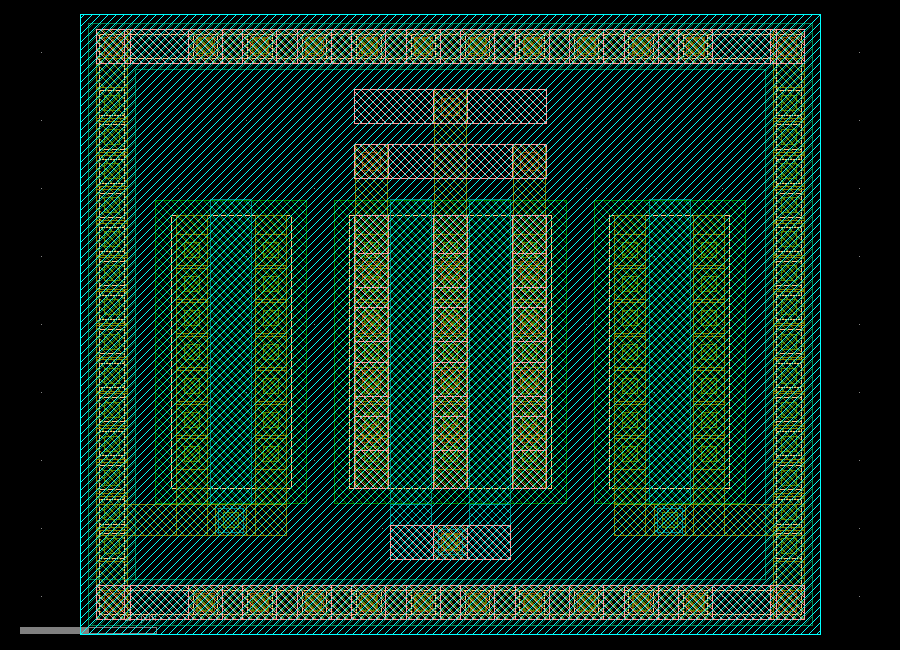

In [ ]:
from glayout import nmos, pmos, mimcap, resistor

nfet = nmos(pdk, width=4, length=0.6, fingers=2, multipliers=1,
            with_tie=True, with_dummy=True, with_dnwell=False,
            with_substrate_tap=False)
print("netlist nodes:", nfet.info["netlist"].nodes)
show(nfet)

/tmp/ipykernel_1714011/923196237.py:7: UserWarning: Unnamed cells, 1 in 'Unnamed_500e469c'
  comp_or_path.write_gds(path)
2026-07-21 16:23:38.067 | INFO     | gdsfactory.component:_write_library:1851 - Wrote to '/home/irman/gLayout/datasets_netlist_to_gdsii/out/_preview.gds'


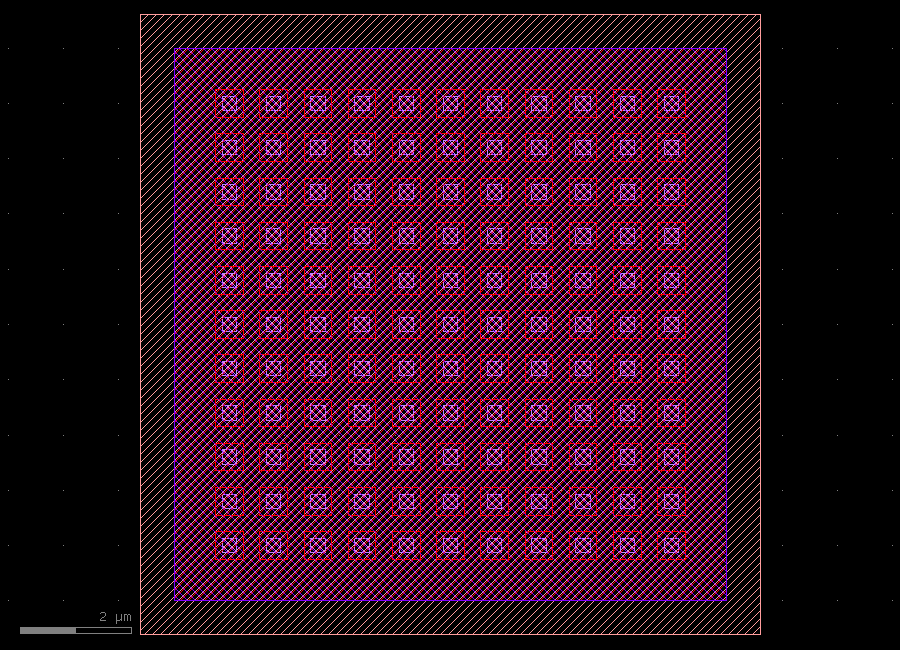

In [ ]:
# NOTE: pmos uses `dnwell=` (nmos uses `with_dnwell=`)
pfet = pmos(pdk, width=6, length=0.6, fingers=3, dnwell=False,
            with_substrate_tap=False)
cap  = mimcap(pdk, size=(10.0, 10.0))     # gf180 ~1.0 fF/um^2 -> ~100 fF
res  = resistor(pdk, width=1.0, length=4.0, num_series=3, with_tie=True)
show(cap)

## 2. Interdigitized matched pair (ABAB…) → current mirror

`two_nfet_interdigitized(pdk, numcols, width, length, fingers)` places
`A B A B …`. Ports are row-spanning straps `A_drain_E`, `B_gate_W`, …

**The one rule that trips everyone:** to use `smart_route`'s specialized
matched-array router you must (1) `top.add_ports(ref.get_ports_list(),
prefix="mir_")` and (2) pass the **prefixed port fetched from `top`**, plus
`ref` and `top`:

/tmp/ipykernel_1714011/923196237.py:7: UserWarning: Unnamed cells, 1 in 'mirror$1'
  comp_or_path.write_gds(path)
2026-07-21 16:23:43.708 | INFO     | gdsfactory.component:_write_library:1851 - Wrote to '/home/irman/gLayout/datasets_netlist_to_gdsii/out/_preview.gds'


pair netlist nodes: ['VDD1', 'VDD2', 'VSS1', 'VSS2', 'VG1', 'VG2', 'VB']


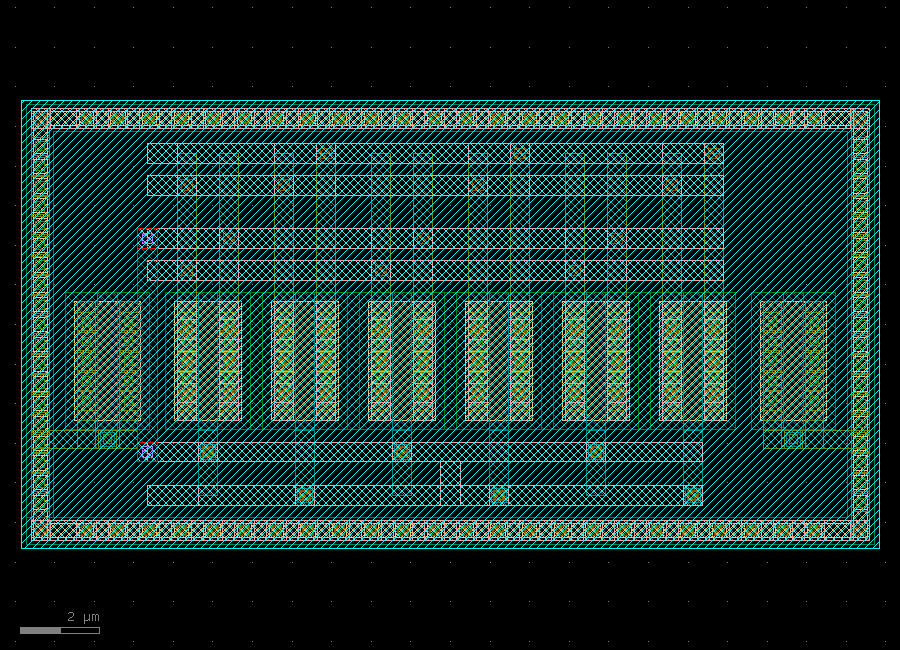

In [ ]:
from glayout import two_nfet_interdigitized, smart_route
from glayout.backend import Component

top = Component(name="mirror")
pair = two_nfet_interdigitized(pdk, numcols=3, width=3, length=0.5,
                               fingers=1, with_substrate_tap=False)
ref = top << pair
top.add_ports(ref.get_ports_list(), prefix="mir_")   # REQUIRED

# current mirror: A diode-connected, B mirrors
for p1, p2 in [("mir_A_drain_E",  "mir_A_gate_E"),
               ("mir_A_gate_E",   "mir_B_gate_E"),
               ("mir_A_source_E", "mir_B_source_E")]:
    top << smart_route(pdk, top.ports[p1], top.ports[p2], ref, top)

print("pair netlist nodes:", pair.info["netlist"].nodes)  # VDD=drain! VSS=source, VG=gate
show(top)

## 3. Common-centroid AB/BA pair (diff-pair layout)

```
A B
B A     device A = top-left + bottom-right (2 x fingers each)
```
`smart_route` supports 14/15 pin pairs here — `A_drain↔B_drain` is broken in
glayout (internal typo) → manual `c_route` on the `_W` ports if ever needed.
The block attaches **no netlist**; build one with
`two_tran_interdigitized_netlist(..., multipliers=2)`.

/tmp/ipykernel_1714011/923196237.py:7: UserWarning: Unnamed cells, 4 in 'cc_diffpair$1'
  comp_or_path.write_gds(path)
2026-07-21 16:23:58.021 | INFO     | gdsfactory.component:_write_library:1851 - Wrote to '/home/irman/gLayout/datasets_netlist_to_gdsii/out/_preview.gds'


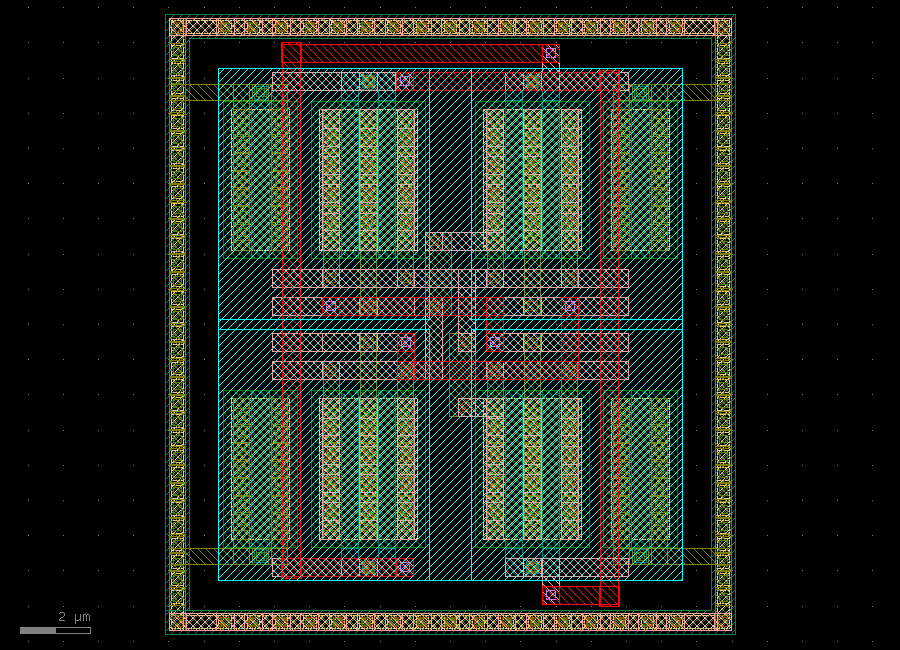

In [ ]:
from glayout import common_centroid_ab_ba
from glayout.placement.two_transistor_interdigitized import two_tran_interdigitized_netlist

top = Component(name="cc_diffpair")
cc = common_centroid_ab_ba(pdk, width=4, fingers=2, length=0.5,
                           n_or_p_fet=True, substrate_tap=True)
ref = top << cc
top.add_ports(ref.get_ports_list(), prefix="dp_")
# diff pair tail: short the sources (supported pair)
top << smart_route(pdk, top.ports["dp_A_source_E"], top.ports["dp_B_source_E"], ref, top)

nl = two_tran_interdigitized_netlist(pdk, width=4, length=0.5, fingers=2,
                                     multipliers=2, with_dummy=True,
                                     n_or_p_fet="nfet", subckt_only=True)
nl.circuit_name = "cc_abba_pair"
top.info["netlist"] = nl
show(top)

## 4. 4T interdigitized (two interdigitized rows, one ring)

`generic_4T_interdigitzed` (glayout's own typo) stacks two AB rows.
Port grammar: `{top|bottom}_{A|B}_{source|drain|gate}_{NESW}`.
Cross-row smart_route: **same-letter combos only** (A on the W flank,
`top_B_source↔bottom_B_drain` on E). Cross-row `B_drain↔B_drain` → manual
`c_route` on the `_E` ports.


 result of check_route:  True


/tmp/ipykernel_1714011/923196237.py:7: UserWarning: Unnamed cells, 4 in 'quad$1'
  comp_or_path.write_gds(path)
2026-07-21 16:24:04.838 | INFO     | gdsfactory.component:_write_library:1851 - Wrote to '/home/irman/gLayout/datasets_netlist_to_gdsii/out/_preview.gds'


4T netlist nodes: ['VDD1', 'VDD2', 'VSS1', 'VSS2', 'VG1', 'VG2', 'VDD3', 'VDD4', 'VSS3', 'VSS4', 'VG3', 'VG4', 'VB']


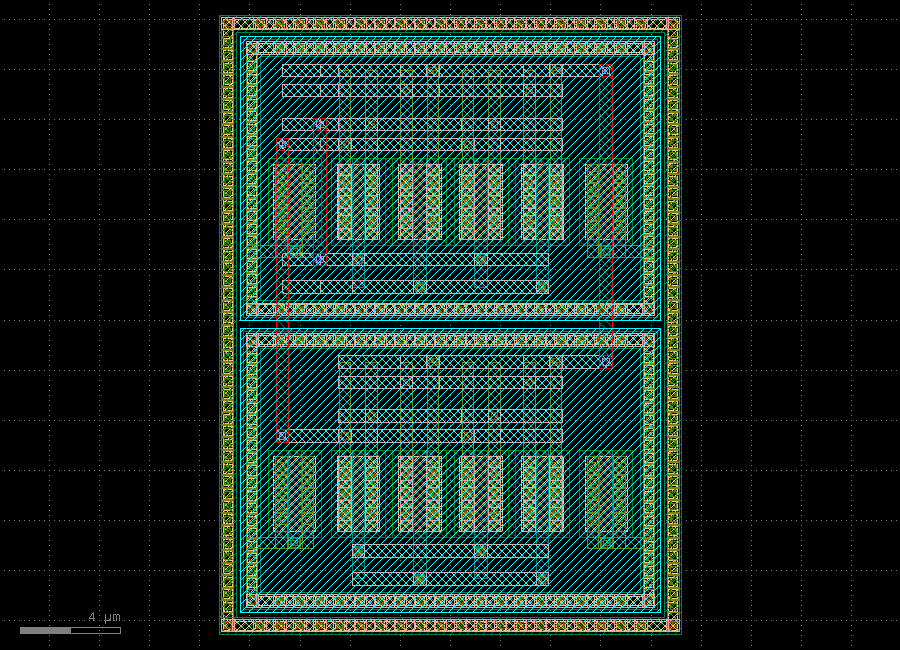

In [ ]:
from glayout import generic_4T_interdigitzed, c_route

top = Component(name="quad")
quad = generic_4T_interdigitzed(pdk, "nfet", "nfet", numcols=2, length=0.5,
                                top_kwargs={"width": 3, "fingers": 1},
                                bottom_kwargs={"width": 3, "fingers": 1})
ref = top << quad
top.add_ports(ref.get_ports_list(), prefix="q_")

top << smart_route(pdk, top.ports["q_top_A_drain_E"], top.ports["q_top_A_gate_E"], ref, top)
top << smart_route(pdk, top.ports["q_top_A_source_W"], top.ports["q_bottom_A_source_W"], ref, top)
top << c_route(pdk, top.ports["q_top_B_drain_E"], top.ports["q_bottom_B_drain_E"], extension=1.5)

print("4T netlist nodes:", quad.info["netlist"].nodes)
show(top)

## 5. The `netlist2gds` compiler — SPICE → GDS automatically

Everything above, driven from a netlist. The pipeline:

```
parse_spice → group_devices → build_block → place_blocks → route_nets → Netlist stitch
```
* mirrors → interdigitized, diff pairs → common-centroid (auto-detected)
* quads → 4T via `hints={("M1","M2","M3","M4"): "interdigitized_4T"}`
* caps → mimcap sized from the SPICE value, R → pseudo-resistor chain
* **`merge="stack"` (default): all transistor + resistor groups are merged
  into ONE stacked macro** — rows x-centered in a single substrate ring
  (nfet singles → nfet pairs/CC → pfet pairs → pfet singles → resistors),
  cross-row nets on E/W flank c_routes, caps in a column beside the stack.
  This is the opamp-style "gabungan" placement: no scattered int-1 / int-2 /
  CC-1 blocks. `merge="none"` gives the old one-block-per-group floorplan.

* 2-transistor nmos current mirror (M1 = diode reference, M2 = mirror)
* auto-detected as role=current_mirror -> interdigitized ABAB placement
.subckt current_mirror iref iout vss
M1 iref iref vss vss nfet_03v3 w=3 l=0.5 m=2 nf=1
M2 iout iref vss vss nfet_03v3 w=3 l=0.5 m=2 nf=1
.ends current_mirror



/tmp/ipykernel_1714011/923196237.py:7: UserWarning: Unnamed cells, 1 in 'current_mirror$1'
  comp_or_path.write_gds(path)
2026-07-21 16:24:07.516 | INFO     | gdsfactory.component:_write_library:1851 - Wrote to '/home/irman/gLayout/datasets_netlist_to_gdsii/out/_preview.gds'


routed 3, skipped 0, failed 0
  [ok]   iref: M1.d <-> M1.g  (smart_route[two_transistor_interdigitized])
  [ok]   iref: M1.g <-> M2.g  (smart_route[two_transistor_interdigitized])
  [ok]   vss: M1.s <-> M2.s  (smart_route[two_transistor_interdigitized])


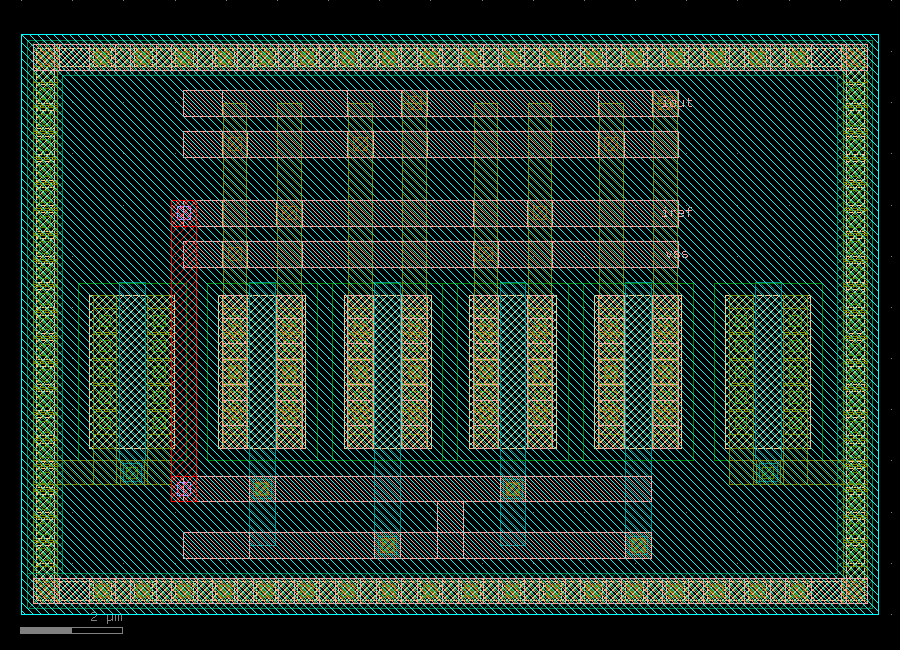

In [ ]:
from netlist2gds import compile_netlist

src = (DATASET / "examples/netlists/current_mirror.sp").read_text()
print(src)
res = compile_netlist(pdk, src)
print(res.report.summary())
show(res.component)

In [ ]:
# the stitched hierarchical SPICE for LVS / simulation:
print(res.spice())

.subckt two_trans_interdigitized VDD1 VDD2 VSS1 VSS2 VG1 VG2 VB l=0.5 w=3.0 m=1 
XA VDD1 VG1 VSS1 VB nfet_03v3 l=0.5 w=3.0 m=2
XB VDD2 VG2 VSS2 VB nfet_03v3 l=0.5 w=3.0 m=2
XDUMMY VB VB VB VB nfet_03v3 l=0.5 w=3.0 m=2
.ends two_trans_interdigitized

.subckt current_mirror iref iout vss
X0 iref iout vss vss iref iref vss two_trans_interdigitized l=0.5 w=3.0 m={1}
.ends current_mirror


### 5T OTA (+ RC snubber) — one merged stack

Bottom→top inside one ring: tail sink M5, CC diff pair M1/M2, interdigitized
pmos mirror M3/M4, resistor R1. The MIM cap C1 sits beside the stack.

/home/irman/gLayout/datasets_netlist_to_gdsii/netlist2gds/compiler.py:54: UserWarning: Unnamed cells, 8 in 'ota_5t$1'
  self.component.write_gds(p)
2026-07-21 16:24:28.149 | INFO     | gdsfactory.component:_write_library:1851 - Wrote to '/home/irman/gLayout/datasets_netlist_to_gdsii/out/nb_ota_5t.gds'
/tmp/ipykernel_1714011/923196237.py:7: UserWarning: Unnamed cells, 8 in 'ota_5t$1'
  comp_or_path.write_gds(path)
2026-07-21 16:24:28.150 | INFO     | gdsfactory.component:_write_library:1851 - Wrote to '/home/irman/gLayout/datasets_netlist_to_gdsii/out/_preview.gds'


routed 10, skipped 0, failed 0
  [ok]   n1: M3.d <-> M3.g  (smart_route[two_transistor_interdigitized])
  [ok]   n1: M3.g <-> M4.g  (smart_route[two_transistor_interdigitized])
  [ok]   n1: M3.d <-> M1.d  (smart:S->N)
  [ok]   tail: M1.s <-> M2.s  (smart_route[common_centroid_ab_ba])
  [ok]   tail: M1.s <-> M5.d  (smart:E->W)
  [ok]   vss: C1.n <-> M5.s  (smart:S->W)
  [ok]   vout: R1.p <-> M4.d  (smart:S->W)
  [ok]   vout: M4.d <-> M2.d  (smart:E->E)
  [ok]   vdd: M3.s <-> M4.s  (smart_route[two_transistor_interdigitized])
  [ok]   rc1: R1.n <-> C1.p  (smart:E->S)


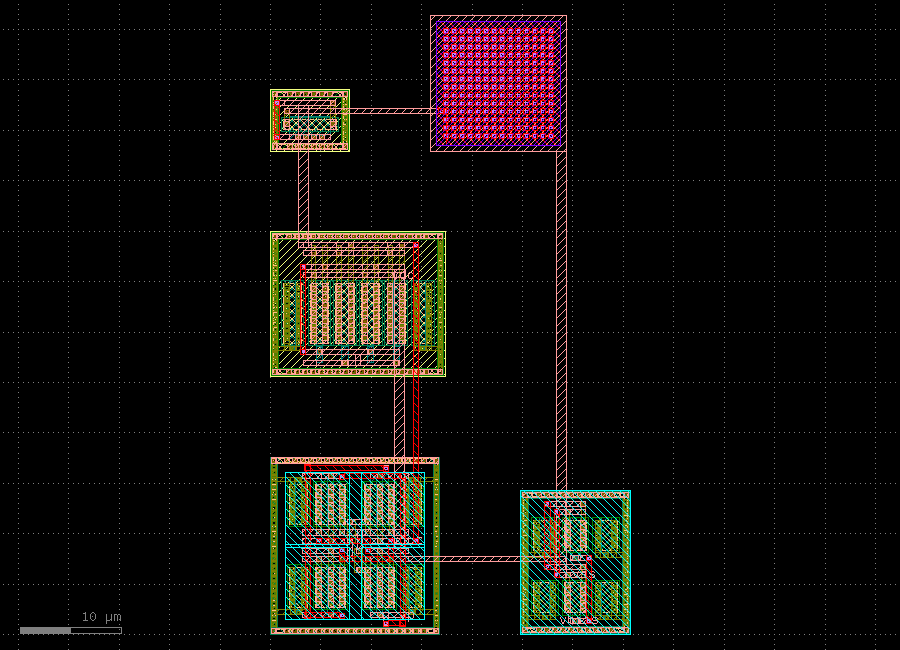

In [ ]:
res = compile_netlist(pdk, (DATASET / "examples/netlists/ota_5t.sp").read_text())
print(res.report.summary())
res.write_gds(str(OUT / "nb_ota_5t.gds"))
show(res.component)

### Two-stage Miller opamp — 6 rows + cap, one macro

M7 & M5 (nfet singles) → M1/M2 CC diff pair → M3/M4 pfet mirror → M6 pfet CS
→ R1 on top, single shared ring, Miller cap beside it.

/home/irman/gLayout/datasets_netlist_to_gdsii/netlist2gds/compiler.py:54: UserWarning: Unnamed cells, 12 in 'opamp_two_stage$1'
  self.component.write_gds(p)
2026-07-21 16:24:52.451 | INFO     | gdsfactory.component:_write_library:1851 - Wrote to '/home/irman/gLayout/datasets_netlist_to_gdsii/out/nb_opamp_two_stage.gds'
/tmp/ipykernel_1714011/923196237.py:7: UserWarning: Unnamed cells, 12 in 'opamp_two_stage$1'
  comp_or_path.write_gds(path)
2026-07-21 16:24:52.453 | INFO     | gdsfactory.component:_write_library:1851 - Wrote to '/home/irman/gLayout/datasets_netlist_to_gdsii/out/_preview.gds'


routed 14, skipped 0, failed 0
  [ok]   n1: M3.d <-> M3.g  (smart_route[two_transistor_interdigitized])
  [ok]   n1: M3.g <-> M4.g  (smart_route[two_transistor_interdigitized])
  [ok]   n1: M3.d <-> M1.d  (smart:S->N)
  [ok]   tail: M1.s <-> M2.s  (smart_route[common_centroid_ab_ba])
  [ok]   tail: M1.s <-> M5.d  (smart:E->W)
  [ok]   vss: M5.s <-> M7.s  (smart:E->W)
  [ok]   n2: R1.p <-> M4.d  (smart:S->W)
  [ok]   n2: M4.d <-> M2.d  (smart:E->E)
  [ok]   n2: M2.d <-> M6.g  (smart:E->S)
  [ok]   vdd: M3.s <-> M4.s  (smart_route[two_transistor_interdigitized])
  [ok]   vdd: M3.s <-> M6.s  (smart:E->W)
  [ok]   vout: C1.n <-> M6.d  (smart:S->N)
  [ok]   vout: M6.d <-> M7.d  (smart:S->W)
  [ok]   cx: R1.n <-> C1.p  (smart:E->W)


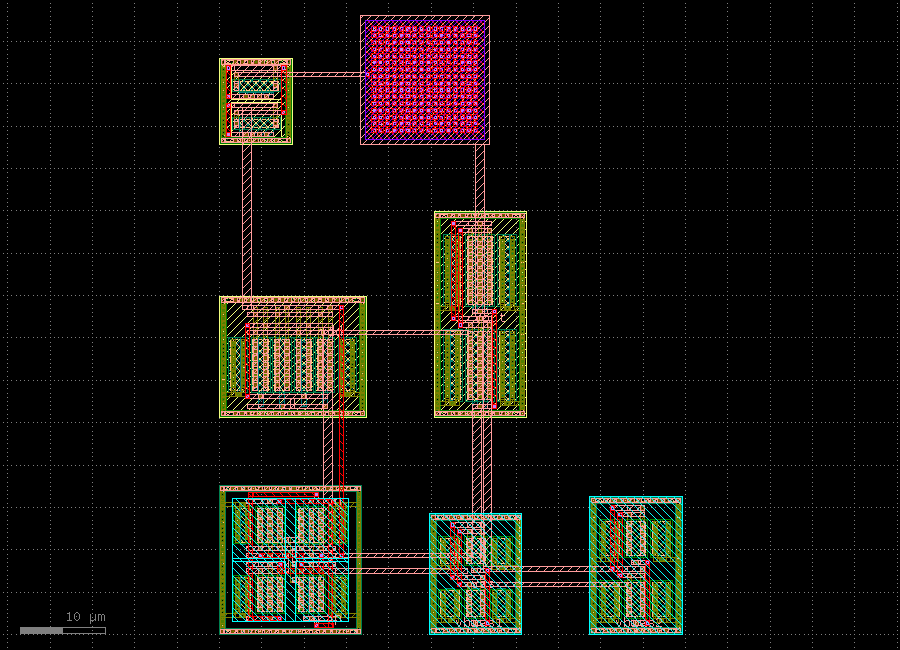

In [ ]:
from netlist2gds import NetlistToGDS

compiler = NetlistToGDS(
    pdk,
    group_params={("C1",): {"size": (14.0, 14.0)},
                  ("R1",): {"num_series": 2, "width": 1.0, "length": 4.0}},
    diff_pair_style="common_centroid",
    cap_density_fF_um2=1.0)
res = compiler.compile((DATASET / "examples/netlists/opamp_two_stage.sp").read_text())
print(res.report.summary())
res.write_gds(str(OUT / "nb_opamp_two_stage.gds"))
show(res.component)

### Inspecting + patching a result

`CompilationResult` keeps every intermediate product. `[FAIL]` routes are
never fatal — patch them manually and re-write the GDS:

In [ ]:
for b in res.blocks:
    print(f"{b.name:22s} {b.group.style:18s} {b.group.device_names()}")

# manual patch pattern (nothing failed here, shown for reference):
# blk = res.block_for("M6")
# res.component << c_route(pdk, blk.port("M6.d", "E"), some_other_port, extension=2)
# res.write_gds(str(OUT / "patched.gds"))
print()
print(res.spice().splitlines()[-9:])

G0_M1_M2               common_centroid    ['M1', 'M2']
G1_M3_M4               interdigitized     ['M3', 'M4']
G2_M5                  single             ['M5']
G3_M6                  single             ['M6']
G4_M7                  single             ['M7']
G5_R1                  res                ['R1']
G6_C1                  cap                ['C1']

['.subckt opamp_two_stage vp vn vout vbias1 vbias2 vdd vss', 'X0 n1 n2 tail tail vp vn vss cc_abba_pair l=0.6 w=4.0 m={1}', 'X1 n1 n2 vdd vdd n1 n1 vdd two_trans_interdigitized l=0.6 w=6.0 m={1}', 'X2 tail vbias1 vss vss m5_dum NMOS l=1.0 w=3.0', 'X3 vout n2 vdd vdd m6_dum PMOS l=0.6 w=8.0', 'X4 vout vbias2 vss vss m7_dum NMOS_1 l=1.0 w=4.0', 'X5 n2 cx n2 PMOS_RES', 'X6 cx vout MIMCap l=14.0 w=14.0', '.ends opamp_two_stage']


## Next steps (sign-off)

The compiler guarantees *topology* (every net routed or reported), not
DRC/LVS cleanliness. Run the usual gf180 sign-off loop on `out/*.gds`
(magic/klayout DRC, netgen LVS against `result.spice()`, then PEX) — the same
flow as `notebook/GLayout_RF_EnergyHarvester_Signoff.ipynb` in this repo.

Known quirks are catalogued in `knowledge/routing_rules.md`.